<a href="https://colab.research.google.com/github/dhkarnati-dotcom/dhkarnati-DataScience-GenAI-Submissions/blob/main/2_05_Exploratory_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=1xqQczl0FG-qtNA2_WQYuWePW9oU8irqJ)

# 2.05 Exploratory Data Analysis (EDA)
We have seen some early examples of EDA in the previous notebooks. This session will expand on this with more examples - specifically a dataset on student performance. You can find the data on my.wbs as "students.csv" (in week 3, asynchronous tasks). As such, we start by importing the data:

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from google.colab import files
upload = files.upload()

Saving titanic.csv to titanic.csv


We can now import the data into pandas as before:

In [34]:
passengers = pd.read_csv('titanic.csv')
passengers.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


We can find the number of rows and columns with ".shape":

In [23]:
passengers.shape

(891, 12)

891 rows and 12 columns. We can get information about the data using the _info_ function:

In [5]:
passengers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


We can see from this our data items are of the type 'object' (meaning string) or int64 (64-bit integers). We can also see that each has "1000 non-null" records and there are "1000 entries". Seemingly there is no missing data but we can of course verify that with code we used in our previous pandas' Notebooks:

In [6]:
passengers.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


No missing data! If we had found some there are various options including deleting the rows (see the previous Notebook) effected or even deleting the columns. If we want to check if its sensible to delete a column we may want to see the percentage of the column's data that is missing:

In [7]:
# Percent of data which is not available
passengers.isnull().sum()/len(passengers) * 100

,0
PassengerId,0.000000
Survived,0.000000
Pclass,0.000000
Name,0.000000
Sex,0.000000
Age,19.865320
SibSp,0.000000
Parch,0.000000
Ticket,0.000000
Fare,0.000000


We can find the number of unique and duplicated rows:

In [8]:
passengers.duplicated().value_counts()

,count
False,891


No duplicates (i.e. there are 1000 records for which its False that the record is a duplicate). Pandas will also give us summary statistics about this data:

In [9]:
passengers.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


We can see that only three of the columns have been "described" ... the three that were numeric (int64). For each, we get a range of useful measures including the mean average, the standard deviation, minimum and maximum values, and the 25th, 50th (median) and 75th percentyles.

### Visualising the Data

[]

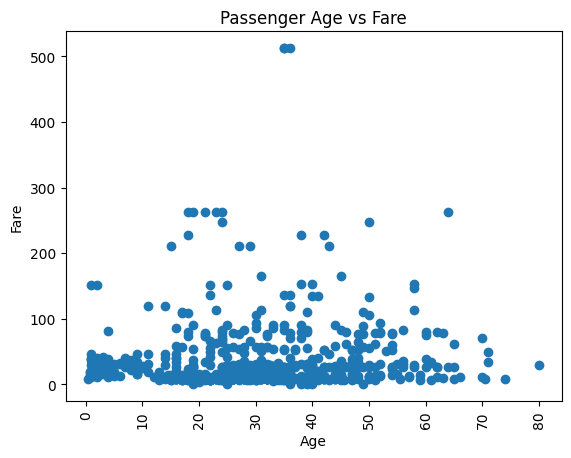

In [24]:
plt.scatter(passengers['Age'], passengers['Fare']) # create a scatter chart of the two values
# note we use a "\" symbol so that the apostrophy doesn't close the string
plt.xlabel('Age') # x-axis is age
plt.xticks(rotation=90) # rotate x labels 90 degrees (vertical)
plt.ylabel('Fare') # y-axis is fare
plt.title('Passenger Age vs Fare') # add title
plt.plot() # plot the chart to screen

Interstingly if you parents had masters-level education your math score is lower! Let's try another:

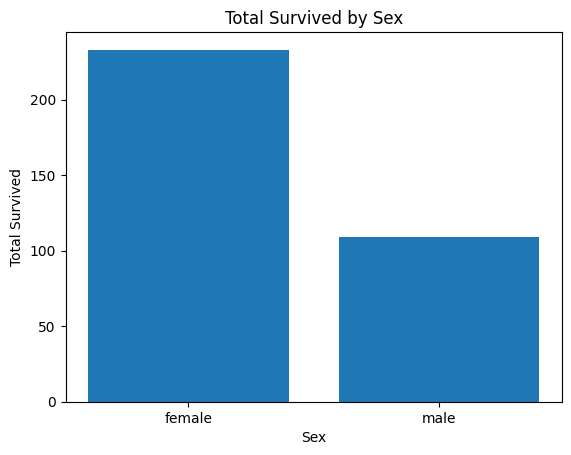

In [25]:
survivors_by_sex = passengers.groupby('Sex')['Survived'].sum()
plt.bar(survivors_by_sex.index, survivors_by_sex.values)
plt.xlabel('Sex')
plt.ylabel('Total Survived')
plt.title('Total Survived by Sex')
plt.show()

### Visualizing Survivors by Other Dimensions (Pclass & Age)

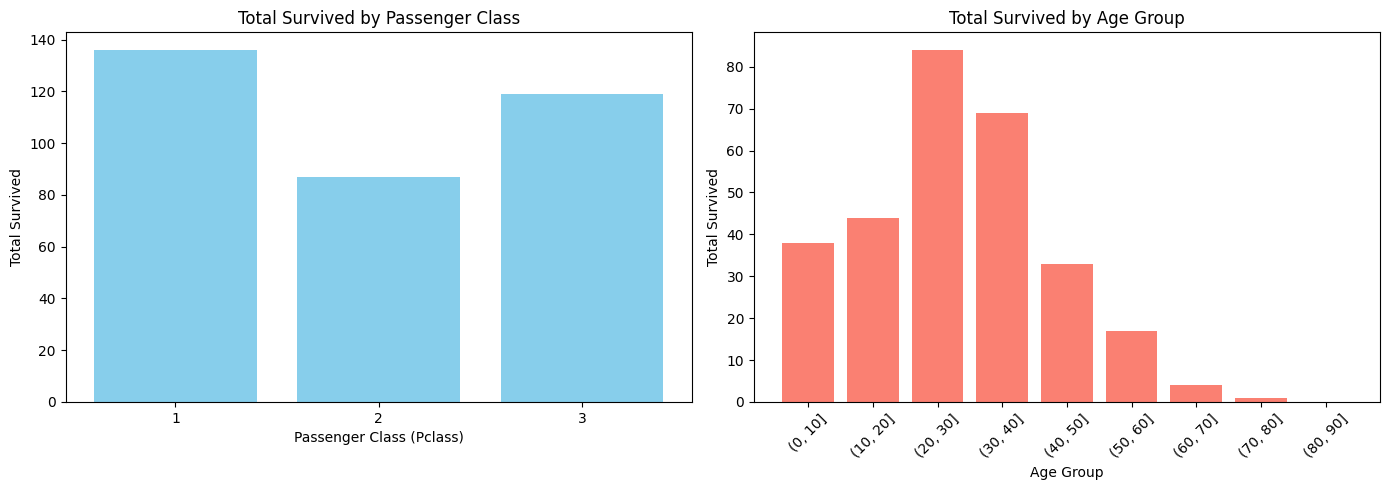

In [26]:
# Calculate total survivors grouped by Passenger Class (Pclass)
survivors_by_class = passengers.groupby('Pclass')['Survived'].sum()

# Calculate total survivors grouped by Age (binned into 10-year groups)
passengers['AgeGroup'] = pd.cut(passengers['Age'], bins=range(0, 91, 10))
survivors_by_age = passengers.groupby('AgeGroup', observed=False)['Survived'].sum()

# Create subplots to show both axes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Survivors by Class
ax1.bar(survivors_by_class.index.astype(str), survivors_by_class.values, color='skyblue')
ax1.set_xlabel('Passenger Class (Pclass)')
ax1.set_ylabel('Total Survived')
ax1.set_title('Total Survived by Passenger Class')

# Plot 2: Survivors by Age Group
ax2.bar(survivors_by_age.index.astype(str), survivors_by_age.values, color='salmon')
ax2.set_xlabel('Age Group')
ax2.set_ylabel('Total Survived')
ax2.set_title('Total Survived by Age Group')
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Again, perhaps unsurprisingly, there seems to be good correlation between maths performance and reading performance (they trend together).

We may also want to see how "normal" our data is - i.e. does it follow a [normal distribution](https://en.wikipedia.org/wiki/Normal_distribution). Let's check with a histogram:

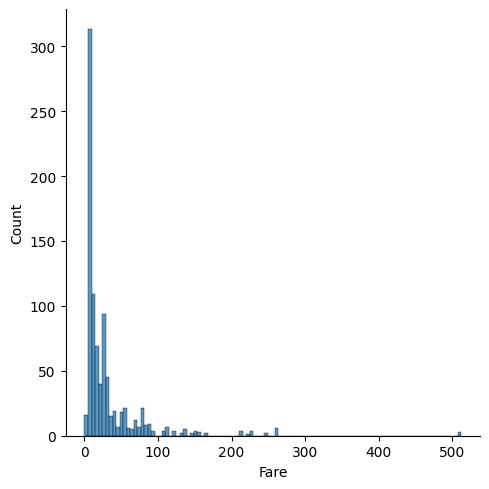

In [19]:
ax = sns.displot(passengers['Fare'])

Whilst this is not exactly normal - slightly skewed - its probably fine in practice.

We can use the _pairplot( )_ method to visualise pairs of variables:

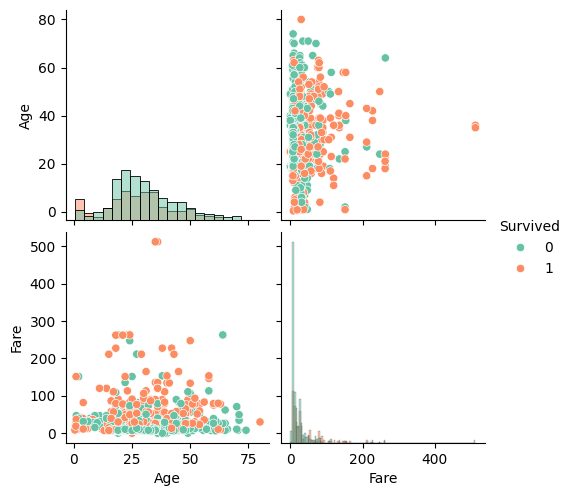

In [35]:
# Using hue='Survived' lets you see the distribution of survivors across Age and Fare
sns.pairplot(data=passengers[['Age', 'Fare', 'Survived']], hue='Survived', diag_kind='hist', palette='Set2')
plt.show()

Here we have the scatter plot when comparing two variables, and when its only a single variable we have a histogram.

We may also decide to remove a variable:

In [32]:
passengers = passengers.drop(['Survived'], axis=1, errors='ignore')
passengers.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,AgeGroup
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,"(20, 30]"
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,"(30, 40]"
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,"(20, 30]"
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,"(30, 40]"
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,"(30, 40]"


Obviously don't drop lunch in the real-world ... you will get hungry.

And that's it! There are of course many of things we could do but this is a fairly typical example of an EDA process. Well done :)

